In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

In [2]:
df= pd.read_csv("iris.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [4]:
df.drop("Id", axis=1, inplace=True)

In [5]:
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

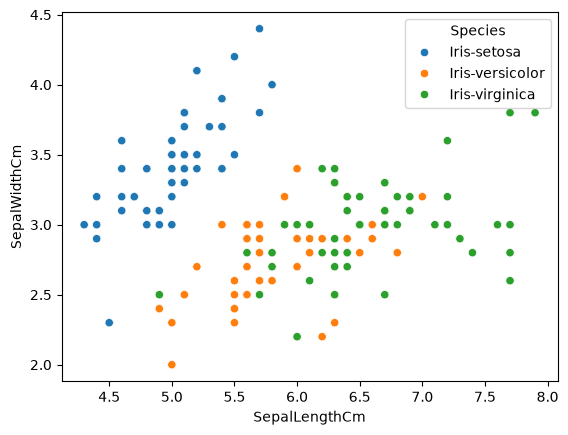

In [6]:
sns.scatterplot(x=df["SepalLengthCm"], y=df["SepalWidthCm"], hue=df["Species"])
plt.show()

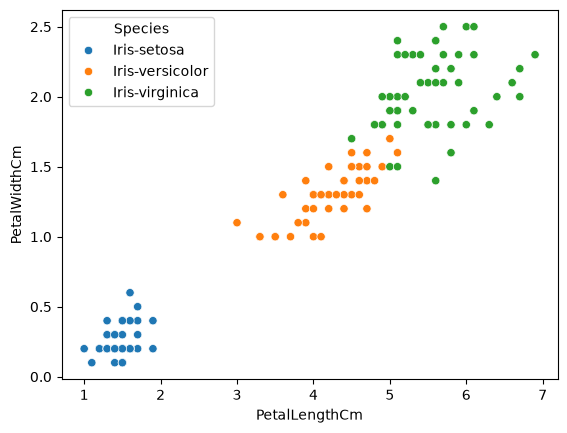

In [7]:
sns.scatterplot(x=df["PetalLengthCm"], y=df["PetalWidthCm"], hue=df["Species"])
plt.show()

In [8]:
X= df.drop("Species", axis=1).values
y=df["Species"].values

In [9]:
from sklearn.preprocessing import LabelEncoder

le= LabelEncoder()
y= le.fit_transform(y)
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [12]:
X_train= torch.tensor(X_train, dtype=torch.float32)
X_test= torch.tensor(X_test, dtype=torch.float32)

y_train= torch.tensor(y_train, dtype=torch.long)
y_test= torch.tensor(y_test, dtype=torch.long)

In [13]:
from torch import nn

In [14]:
X_train.shape

torch.Size([120, 4])

In [15]:
class IrisClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear_layer_stack= nn.Sequential(
            nn.Linear(in_features=4, out_features=10),
            nn.ReLU(),
            nn.Linear(in_features=10, out_features=10),
            nn.ReLU(),
            nn.Linear(in_features=10, out_features=3)
        )

    def forward(self, x:torch.tensor):
        return self.linear_layer_stack(x)

In [16]:
torch.manual_seed(42)
model= IrisClassifier()

In [17]:
model(X_train[:5])

tensor([[ 0.0502,  0.1405,  0.2161],
        [ 0.0503, -0.0900,  0.3955],
        [ 0.0325, -0.1054,  0.4160],
        [ 0.0527,  0.1584,  0.2154],
        [ 0.0423, -0.0730,  0.3758]], grad_fn=<AddmmBackward0>)

In [18]:
loss_fn= nn.CrossEntropyLoss()
optimizer= torch.optim.Adam(params=model.parameters(), lr=0.01)

In [19]:
from torchmetrics.classification import MulticlassAccuracy 

In [20]:
accuracy= MulticlassAccuracy(num_classes=3)

In [21]:
epochs=100

train_losses=[]
test_losses=[]

for epoch in range(epochs):
    model.train()

    logits= model(X_train)
    loss= loss_fn(logits, y_train)
    train_losses.append(loss.item())
    
    pred= torch.argmax(logits, dim=1)
    acc= accuracy(pred, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.inference_mode():

        test_logits= model(X_test)
        test_loss= loss_fn(test_logits, y_test) 
        test_losses.append(test_loss.item())
        
        test_pred= torch.argmax(test_logits, dim=1)
        test_acc= accuracy(test_pred, y_test)

    if epoch % 10 == 0:
        print(f"Epoch:{epoch}, Loss:{loss.item()}, Accuracy:{acc.item()}, Test Loss:{test_loss.item()}, Test Accuracy:{test_acc.item()}")

Epoch:0, Loss:1.100983738899231, Accuracy:0.3333333432674408, Test Loss:1.081264615058899, Test Accuracy:0.3333333432674408
Epoch:10, Loss:0.8904960751533508, Accuracy:0.6666666865348816, Test Loss:0.8554353713989258, Test Accuracy:0.6666666865348816
Epoch:20, Loss:0.5674903392791748, Accuracy:0.7083333730697632, Test Loss:0.5386632680892944, Test Accuracy:0.7666666507720947
Epoch:30, Loss:0.39065825939178467, Accuracy:0.9416667222976685, Test Loss:0.3775448799133301, Test Accuracy:0.9666666984558105
Epoch:40, Loss:0.2657257616519928, Accuracy:0.9750000238418579, Test Loss:0.25830402970314026, Test Accuracy:1.0
Epoch:50, Loss:0.1606215387582779, Accuracy:0.9750000238418579, Test Loss:0.15987847745418549, Test Accuracy:0.9666666984558105
Epoch:60, Loss:0.10213644802570343, Accuracy:0.9750000238418579, Test Loss:0.1089756190776825, Test Accuracy:0.9666666984558105
Epoch:70, Loss:0.07742058485746384, Accuracy:0.9750000238418579, Test Loss:0.08140674233436584, Test Accuracy:0.9666666984558

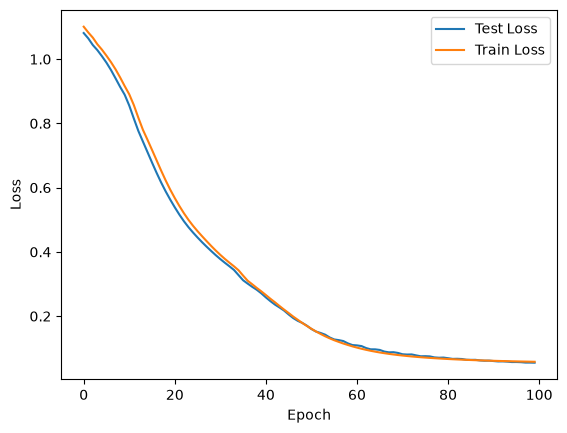

In [22]:
plt.plot(test_losses, label="Test Loss")
plt.plot(train_losses, label="Train Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [23]:
from torchmetrics.classification import MulticlassConfusionMatrix

In [24]:
cm= MulticlassConfusionMatrix(num_classes=3)

In [25]:
matrix= cm(test_pred, y_test)

In [26]:
matrix

tensor([[10,  0,  0],
        [ 0, 10,  0],
        [ 0,  0, 10]])

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

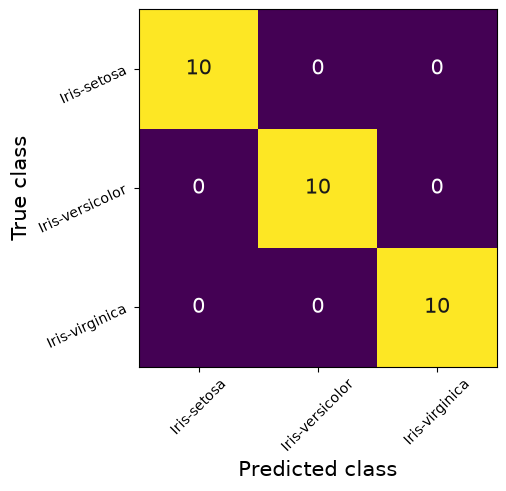

In [27]:
cm.plot(matrix, labels=le.classes_.tolist())